# 02 — Featurization

Build the modeling dataset, inspect the feature matrix, and explore
feature groups before running full experiments.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.modeling.config import load_dataset_config
from src.modeling.dataset import build_modeling_dataset
from src.modeling.features import (
    build_feature_pipeline,
    featurize,
    get_feature_names,
    build_feature_group_index,
)

sns.set_theme(style="whitegrid")

## 1. Load config and build modeling dataset

In [4]:
cfg = load_dataset_config(ROOT / "config/dataset/modeling_dataset_aero_anaero.yaml")

In [5]:
df = build_modeling_dataset(cfg, root=ROOT)
df.head()

2026-06-25 15:37:08.232 | INFO     | src.modeling.dataset:build_modeling_dataset:72 - loading curves: [PosixPath('/scratch/chinasse/MicrobeNet/data/processed/aerobic_tidy_curves.csv'), PosixPath('/scratch/chinasse/MicrobeNet/data/processed/anaerobic_tidy_curves.csv')]
2026-06-25 15:37:08.242 | INFO     | src.modeling.dataset:_load_curves:41 - loaded 2 curves files, total shape: 1260 rows x 17 cols
2026-06-25 15:37:08.244 | INFO     | src.modeling.dataset:build_modeling_dataset:77 - removed water controls, shape: 1155 rows x 17 cols
2026-06-25 15:37:08.245 | INFO     | src.modeling.dataset:build_modeling_dataset:81 - removed `other` strains, shape: 1111 rows x 17 cols
2026-06-25 15:37:08.247 | INFO     | src.modeling.dataset:build_modeling_dataset:85 - removed `empty` strains, shape: 1078 rows x 17 cols
2026-06-25 15:37:08.247 | INFO     | src.modeling.dataset:build_modeling_dataset:90 - loading strain metadata: /scratch/chinasse/MicrobeNet/data/external/strains_metadata.csv
2026-06-25 

,exp_id,date,well_id,row,col,well_index,strain_name,media_name,atmosphere,temperature,...,ncbi_taxon_id,assembly_level,genome_size_bp,gc_content_pct,num_contigs,n50,sequence_hash,date_retrieved,resolution_method,requires_verification
0,aerobic_a_25,20260325,a_1_0,a,1,0,escherichia coli k12,lb,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no
1,aerobic_a_25,20260325,a_2_1,a,2,1,escherichia coli k12,mb,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no
2,aerobic_a_25,20260325,a_3_2,a,3,2,escherichia coli k12,nb,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no
3,aerobic_a_25,20260325,a_4_3,a,4,3,escherichia coli k12,bhi,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no
4,aerobic_a_25,20260325,a_5_4,a,5,4,escherichia coli k12,mrs,aerobic,25.0,...,562,scaffold,4685496,50.7,63,149239,9a7a1ab441a951df4b1e30be071faaee595fd48de0f8e7...,2026-06-24,NCBI assembly search by ATCC number,no


In [16]:
print(f"Shape: {df.shape}")
print(f"Strains: {df['strain_name'].nunique()}")
print(f"Strains: {df['strain_name'].unique()}")
print(f"Media: {df['media_name'].nunique()}")
print(f"Media: {df['media_name'].unique()}")
print(f"Growth class distribution:\n{df['growth_class'].value_counts()}")

Shape: (1078, 30)
Strains: 25
Strains: <ArrowStringArray>
[         'escherichia coli k12',    'corynebacterium glutamicum',
            'pseudomonas putida',             'bacillus subtilis',
         'escherichia coli bl21',    'streptococcus thermophilus',
      'bifidobacterium animalis',          'acinetobacter baylyi',
           'priestia megaterium',         'gluconobacter oxydans',
      'acetobacter pasteurianus',           'cupriavidus necator',
      'arthrobacter globiformis',      'paracoccus denitrificans',
       'deinococcus radiodurans',            'kocuria rhizophila',
            'micrococcus luteus',             'acetobacter aceti',
        'azotobacter vinelandii',        'caulobacter vibrioides',
     'lactobacillus acidophilus', 'lactiplantibacillus plantarum',
      'pediococcus acidilactici',        'clostridium sporogenes',
      'komagataeibacter xylinus']
Length: 25, dtype: str
Media: 11
Media: <ArrowStringArray>
['lb', 'mb', 'nb', 'bhi', 'mrs', 'thy', 'tsb'

## 2. Build and inspect feature pipeline

In [8]:
# Build (unfitted) transformer
ct, feature_cols, fgm = build_feature_pipeline(cfg, df, root=ROOT)
print(f"Raw feature columns: {feature_cols}")
print(f"Feature group map: {fgm}")

Raw feature columns: ['strain_name', 'media_name', 'atmosphere', 'temperature']
Feature group map: {'strain_name': 'strain', 'media_name': 'media', 'atmosphere': 'condition', 'temperature': 'condition'}


In [10]:
# Fit on all data (EDA only — NOT for CV reporting)
ct.fit(df)
X = ct.transform(df)
feature_names = get_feature_names(ct)

print(f"X shape: {X.shape}")
print(f"Feature names ({len(feature_names)}): {feature_names}")

X shape: (1078, 39)
Feature names (39): ['oh_strain_name__strain_name_acetobacter aceti', 'oh_strain_name__strain_name_acetobacter pasteurianus', 'oh_strain_name__strain_name_acinetobacter baylyi', 'oh_strain_name__strain_name_arthrobacter globiformis', 'oh_strain_name__strain_name_azotobacter vinelandii', 'oh_strain_name__strain_name_bacillus subtilis', 'oh_strain_name__strain_name_bifidobacterium animalis', 'oh_strain_name__strain_name_caulobacter vibrioides', 'oh_strain_name__strain_name_clostridium sporogenes', 'oh_strain_name__strain_name_corynebacterium glutamicum', 'oh_strain_name__strain_name_cupriavidus necator', 'oh_strain_name__strain_name_deinococcus radiodurans', 'oh_strain_name__strain_name_escherichia coli bl21', 'oh_strain_name__strain_name_escherichia coli k12', 'oh_strain_name__strain_name_gluconobacter oxydans', 'oh_strain_name__strain_name_kocuria rhizophila', 'oh_strain_name__strain_name_komagataeibacter xylinus', 'oh_strain_name__strain_name_lactiplantibacillus pl

In [11]:
# Feature group index (for SHAP grouping)
group_idx = build_feature_group_index(feature_names, fgm)
for group, indices in group_idx.items():
    print(f"{group}: {len(indices)} features (indices {indices[:5]}...)")

strain: 25 features (indices [0, 1, 2, 3, 4]...)
media: 11 features (indices [25, 26, 27, 28, 29]...)
condition: 3 features (indices [36, 37, 38]...)


## 3. Wrapper for notebook exploration

In [12]:
X, y, feat_names, groups, fgm = featurize(df, cfg, target="growth_class", root=ROOT)
print(f"X: {X.shape}, y: {y.shape}, unique groups: {len(np.unique(groups))}")

X: (1078, 39), y: (1078,), unique groups: 25


## 4. Visualize feature matrix

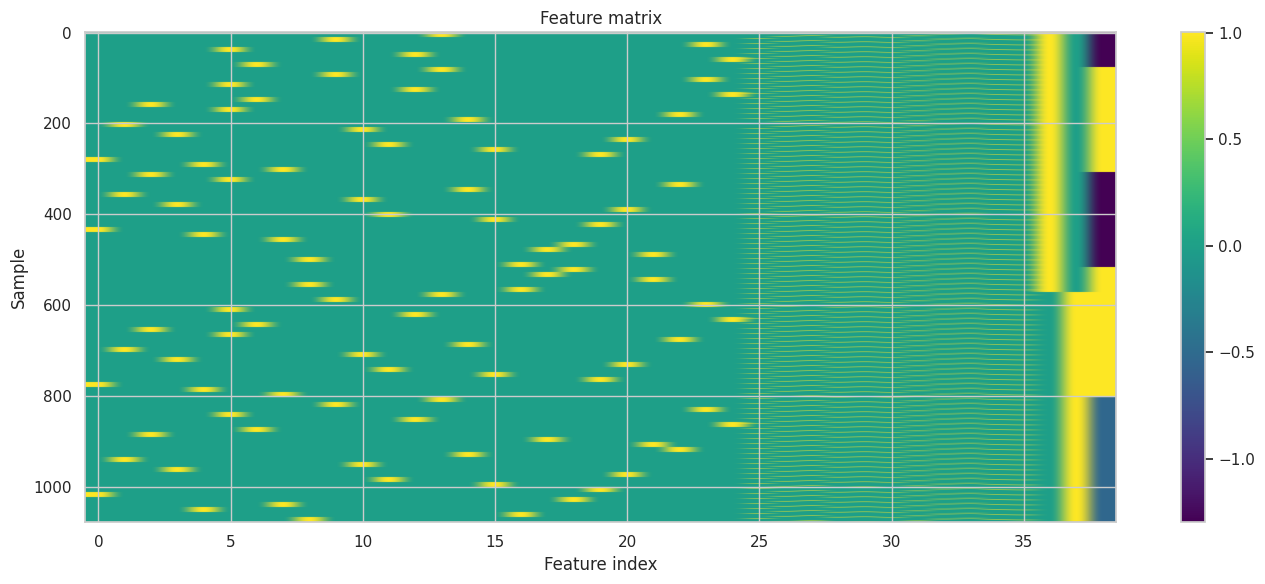

In [15]:
fig, ax = plt.subplots(figsize=(14, 6))
im = ax.imshow(X[:], aspect="auto", cmap="viridis")
ax.set_xlabel("Feature index")
ax.set_ylabel("Sample")
ax.set_title("Feature matrix")
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()